# 06 — Mixed variables: can the GP learn how levels relate?

One continuous `x`, one nominal `z` with three levels: A = f(x), B = -f(x) (correlation -1),
C = g(x), an unrelated function. Checks the fitted level correlations per method, and the
prediction error per level.

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mvlse import Continuous, DesignSpace, Nominal, fit_surrogate

space = DesignSpace({"x": Continuous(0.0, 1.0), "z": Nominal(["A", "B", "C"])})
f = lambda x: np.sin(6 * x) + 0.5 * x
g = lambda x: np.cos(11 * x)
truth = {0: f, 1: lambda x: -f(x), 2: g}

def response(w):
    return np.array([truth[int(k)](x) for x, k in w])

rng = np.random.default_rng(3)
n_per_level = 6
w_train = np.array([[x, k] for k in range(3) for x in (np.arange(n_per_level) + rng.random(n_per_level)) / n_per_level])
y_train = response(w_train)
x_grid = np.linspace(0.0, 1.0, 201)
w_grid = np.array([[x, k] for k in range(3) for x in x_grid])
y_grid = response(w_grid)

expected = np.corrcoef([f(x_grid), -f(x_grid), g(x_grid)])
print("correlation of the true level functions over x (what a perfect model would learn):")
print(pd.DataFrame(expected, index=list("ABC"), columns=list("ABC")).round(2))

correlation of the true level functions over x (what a perfect model would learn):
      A     B     C
A  1.00 -1.00 -0.14
B -1.00  1.00  0.14
C -0.14  0.14  1.00


In [11]:
methods = ["dc", "gower", "hs_full", "hs_dim", "category_wise"]
rows, preds = [], {}
for method in methods:
    model = fit_surrogate(method, space, w_train, y_train, rng=np.random.default_rng(0))
    mu, sd = model.predict(w_grid)
    preds[method] = (mu, sd)
    corr = model.level_correlations().get("z")
    row = {"method": method, "hyperparameters": model.n_hyperparameters}
    if corr is not None:
        row |= {"corr(A,B)": corr[0, 1], "corr(A,C)": corr[0, 2], "corr(B,C)": corr[1, 2]}
    for k, lev in enumerate("ABC"):
        sel = w_grid[:, 1] == k
        row[f"RMSE {lev}"] = np.sqrt(np.mean((mu[sel] - y_grid[sel]) ** 2))
    rows.append(row)
table = pd.DataFrame(rows).set_index("method")
table.round(3)

,hyperparameters,"corr(A,B)","corr(A,C)","corr(B,C)",RMSE A,RMSE B,RMSE C
method,,,,,,,
dc,2,0.000,0.000,0.000,0.072,0.060,0.085
gower,2,0.000,0.000,0.000,0.072,0.060,0.085
hs_full,4,-0.999,-0.121,0.106,0.029,0.025,0.071
hs_dim,4,-0.999,-0.121,0.106,0.029,0.025,0.071
category_wise,3,NaN,NaN,NaN,0.002,0.025,0.478


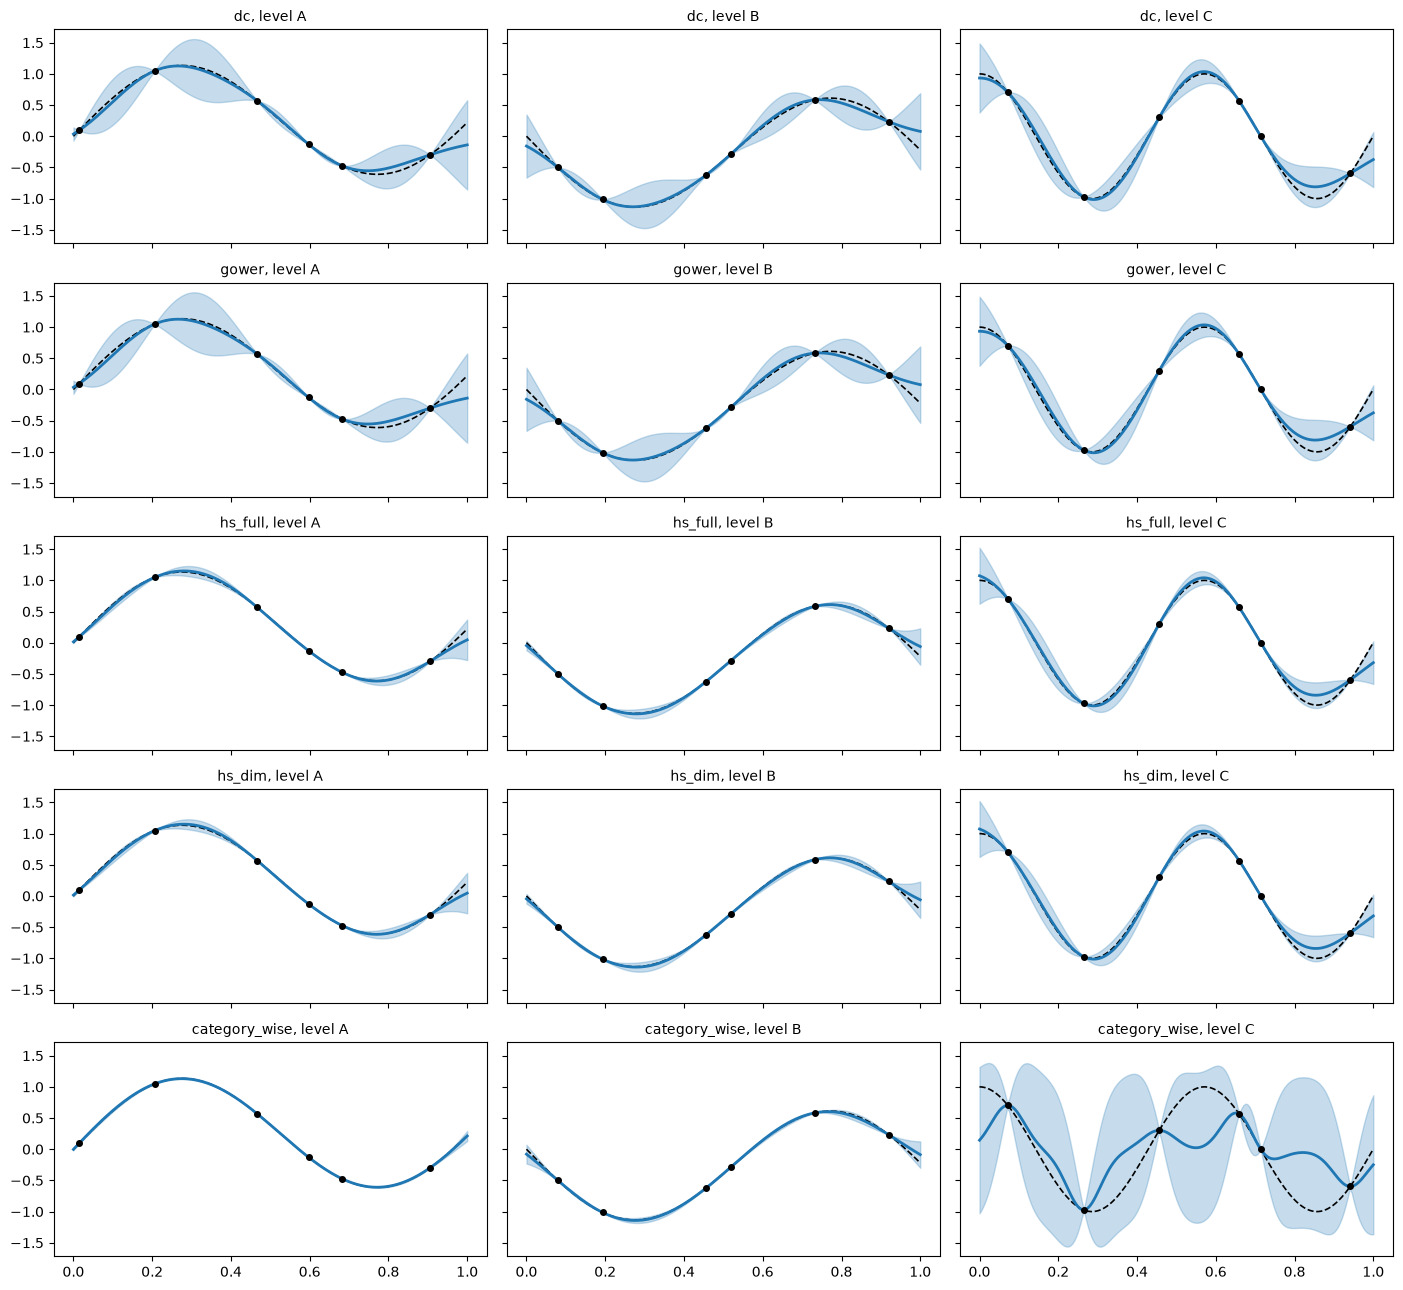

In [12]:
fig, axes = plt.subplots(len(methods), 3, figsize=(14, 2.6 * len(methods)), sharex=True, sharey=True)
for i, method in enumerate(methods):
    mu, sd = preds[method]
    for k, lev in enumerate("ABC"):
        ax = axes[i, k]; sel = w_grid[:, 1] == k; tr = w_train[:, 1] == k
        ax.fill_between(x_grid, (mu - 1.96 * sd)[sel], (mu + 1.96 * sd)[sel], color="C0", alpha=0.25)
        ax.plot(x_grid, y_grid[sel], "k--", lw=1.2)
        ax.plot(x_grid, mu[sel], "C0", lw=2)
        ax.plot(w_train[tr, 0], y_train[tr], "ko", ms=4)
        ax.set_title(f"{method}, level {lev}", fontsize=10)
plt.tight_layout(); plt.show()